Step 1 — Load the data
5–10 minutesImport the necessary libraries and load your existing Banking77 dataset.
Requirements
- Convert the training partition into a pandas DataFrame.
- Inspect its first five rows.
- Display the column names and dataset shape.
- Make sure numerical label IDs can be mapped to human-readable intent names.

In [1]:
from datasets import load_dataset
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

d:\PROGRAMMING_PROJECTS\DS_RP_PROJECTS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_dataset("PolyAI/banking77")
# print(dataset[:5])

In [3]:
train_data = dataset['train']
test_data = dataset['test']

In [4]:
#Convert partitions into pandas dfs
df_tr = pd.DataFrame(train_data)
df_ts = pd.DataFrame(test_data)

In [5]:
df_tr.head()

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11


In [6]:
print('Column names:',df_tr.columns)
print(f'Train dataset shape:{df_tr.shape}')

Column names: Index(['text', 'label'], dtype='str')
Train dataset shape:(10003, 2)


In [7]:
df_tr.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    10003 non-null  str  
 1   label   10003 non-null  int64
dtypes: int64(1), str(1)
memory usage: 737.5 KB


    Step 2 — Class frequency analysis
    Objective
    Determine how many customer messages belong to each banking intent.
    Questions to answer
    - How many unique intent labels are present?
    - How many observations belong to each class?
    - Which five classes have the most observations?
    - Which five classes have the fewest observations?
    - Is the dataset reasonably balanced?

In [8]:
df_tr['text'].nunique()

10003

In [9]:
print('Count of unique labels:')
df_tr['label'].nunique()

Count of unique labels:


77

In [10]:
df_tr['label'].value_counts()

label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64

In [11]:
df_tr['label'].value_counts().head()

label
15    187
28    182
6     181
75    180
19    177
Name: count, dtype: int64

In [12]:
df_tr['label'].value_counts().tail()

label
41    82
18    61
10    59
72    41
23    35
Name: count, dtype: int64

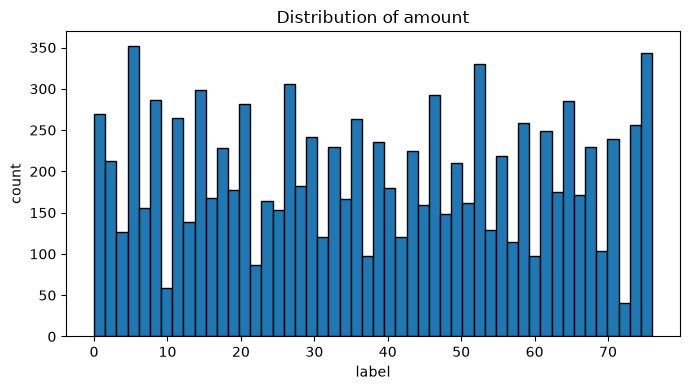

In [13]:
### Vizualize distribution
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df_tr['label'], bins=50, edgecolor='black')
ax.set_xlabel('label')
ax.set_ylabel('count')
ax.set_title('Distribution of amount')
plt.tight_layout()
plt.show()

    Step 3 — Investigate class imbalance
    10 minutesClass frequency tells you the number of samples in each class. Class imbalance analysis helps you interpret those numbers.

    Calculate the following:
    Metric	Your result
    Maximum class frequency	?
    Minimum class frequency	?
    Mean class frequency	?
    Median class frequency	?
    Maximum-to-minimum ratio	?

    The imbalance ratio can be calculated as:
    \[
    \text{Imbalance ratio}=
    \frac{\text{Largest class count}}
    {\text{Smallest class count}}
    \]

    Answer this question:
    Based on the class distribution, do we have sufficient evidence to describe the dataset as reasonably balanced or significantly imbalanced?

    There is no universal imbalance-ratio threshold. Explain your conclusion using the actual frequencies rather than relying on an arbitrary number.

    Do not apply oversampling or undersampling yet.

In [21]:
df_tr['label'].value_counts()
print('Class with the maximum frequency:',df_tr['label'].value_counts().idxmax())

Class with the maximum frequency: 15


In [23]:
print('Class with the minimum frequency:',df_tr['label'].value_counts().idxmin())

Class with the minimum frequency: 23


In [25]:
print(df_tr['label'].value_counts().mean())

129.9090909090909


In [27]:
print(df_tr['label'].value_counts().median())

127.0


In [30]:
print('Imbalance Ratio:',df_tr['label'].value_counts().max()-df_tr['label'].value_counts().min())

Imbalance Ratio: 152


My conclusion would be that i don't know if there is a threshold which will count imbalance-ratio but i do know that label 15 is a lot larger than label 23,Maybe imbalance or balanced i don't know.
I do understand frequency  which is the amount of times we meet the certain amount -<value_counts>-<>helps us with it

## Step 4 — Message-Length Analysis

**Estimated time:** 15 minutes

### 4.1. Objective
Understand the length distribution of customer messages.

### 4.2. Feature Creation

Create two new columns:

| Column | Description |
|---|---|
| `char_length` | Number of characters in the message |
| `word_count` | Number of whitespace-separated words |

**Example:**

| Message | Characters | Words |
|---|---:|---:|
| Card blocked | 12 | 2 |
| My card payment was declined | 28 | 5 |
| Payment failed | 14 | 2 |

**Useful methods:** `str.len()`, `str.split()`, `apply()`, `describe()`

### 4.3. Descriptive Statistics

Calculate the following statistics for both columns:

| Statistic | Characters | Words |
|---|---:|---:|
| Minimum | | |
| Maximum | | |
| Mean | | |
| Median | | |
| Standard deviation | | |
| 25th percentile | | |
| 75th percentile | | |
| 90th percentile | | |
| 95th percentile | | |
| 99th percentile | | |

### 4.4. Visualization

Generate a histogram of the message-length distribution using
the actual training data.

**Word-count intervals:**

- 1–5
- 6–10
- 11–15
- 16–20
- 21–25
- 26–30
- 31–35
- 36+

### 4.5. ML Connection

Message length can influence feature representation,
computational cost, and Transformer token limits.

Word and character counts are useful initial measurements,
although they are not equivalent to Transformer token counts.

In [42]:
df_tr['char_length'] = df_tr['text'].str.len()
df_tr.head()

,text,label,char_length
0,I am still waiting on my card?,11,30
1,What can I do if my card still hasn't arrived ...,11,60
2,I have been waiting over a week. Is the card s...,11,58
3,Can I track my card while it is in the process...,11,59
4,"How do I know if I will get my card, or if it ...",11,54


In [52]:
df_tr['word_count'] = df_tr['text'].str.split().apply(len)
df_tr.head()

,text,label,char_length,word_count
0,I am still waiting on my card?,11,30,7
1,What can I do if my card still hasn't arrived ...,11,60,13
2,I have been waiting over a week. Is the card s...,11,58,12
3,Can I track my card while it is in the process...,11,59,13
4,"How do I know if I will get my card, or if it ...",11,54,15
